In [15]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    TimeSeriesSplit,
    cross_val_score
)

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder,
    PolynomialFeatures
)

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

from sklearn.linear_model import (
    LinearRegression,
    Ridge,
    Lasso
)

from sklearn.tree import DecisionTreeRegressor

from sklearn.neighbors import KNeighborsRegressor

from sklearn.ensemble import GradientBoostingRegressor

from sklearn.dummy import DummyRegressor

from sklearn.metrics import (
    mean_squared_error,
    r2_score
)

from sklearn.base import clone

from sklearn.preprocessing import TargetEncoder

from IPython.display import display
import warnings

warnings.filterwarnings("ignore")

# Reproducibility
RANDOM_STATE = 42

print("Libraries imported successfully!")

Libraries imported successfully!


In [16]:
# Load dataset
df = pd.read_csv("hybrid_student_performance_1200 - hybrid_student_performance_1200.csv")

# Convert timestamp to datetime
df["timestamp"] = pd.to_datetime(
    df["timestamp"],
    errors="coerce"
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (1200, 36)


,student_id,timestamp,year_class,program_stream,age,gender,cgpa_category,academic_satisfaction,study_hours_daily,daily_productivity,...,projects_internships,programming_foundation,events_participation,assignments_on_time,attendance_percentage,strongest_asset,internal_barrier,external_resources,external_pressure,performance_risk_level
0,STU0001,2026-03-29 20:54:43,Second Year (SY),BCA,20,Female,8.5 – 9.4,Neutral,Less than 1 hour,2.0,...,"Yes, actively working on projects/internship","Basic knowledge, learning while practicing",Occasionally participate in events,Often,Above 85%,"Technical/Hard Skills (Coding, Math, Logic)",Lack of Consistency or Determination (Difficul...,Occasionally (When needed),No Impact (Fully supportive environment),Moderate Risk
1,STU0002,2026-03-29 21:20:15,Second Year (SY),BCA,20,Male,8.5 – 9.4,Unsatisfied,1–2 hours,1.0,...,"Yes, actively working on projects/internship","Limited knowledge, theoretical only","Rarely participate, mostly observe",Often,76% – 85%,"Creative/Design Skills (Innovation, UI/UX, Con...",Lack of Consistency or Determination (Difficul...,Occasionally (When needed),Moderate Impact (Occasional disruption),Moderate Risk
2,STU0003,2026-03-29 21:21:35,Second Year (SY),BCA,19,Male,5.0 – 6.9,Neutral,1–2 hours,2.0,...,"Yes, actively working on projects/internship","Basic knowledge, learning while practicing","Rarely participate, mostly observe",Often,Less than 50%,"Technical/Hard Skills (Coding, Math, Logic)",Difficulty with Focus / Concentration,Rarely (Passive),High Impact (Frequent disruption),High Risk
3,STU0004,2026-03-29 21:27:44,Second Year (SY),BCA,19,Female,8.5 – 9.4,Satisfied,1–2 hours,3.0,...,Planning to start a project/internship soon,"Basic knowledge, learning while practicing","Rarely participate, mostly observe",Often,Above 85%,"Management/Execution (Planning, Organizing, Di...",Procrastination / Low Motivation,Occasionally (When needed),High Impact (Frequent disruption),Low Risk
4,STU0005,2026-03-29 22:05:14,Second Year (SY),BCA,20,Female,8.5 – 9.4,Neutral,1–2 hours,2.0,...,Planning to start a project/internship soon,"Basic knowledge, learning while practicing",Occasionally participate in events,Often,76% – 85%,"Management/Execution (Planning, Organizing, Di...",Lack of Consistency or Determination (Difficul...,Occasionally (When needed),High Impact (Frequent disruption),High Risk


PART A – Data Inspection and Potential Leakage

In [17]:
# Dataset dimensions
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# Data types
print("\nData types:")
print(df.dtypes)

# Descriptive statistics
print("\nDescriptive statistics:")
display(df.describe(include="all").T)

# Missing values
missing = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": df.isnull().mean() * 100
})

print("\nMissing values:")
display(missing[missing["Missing Values"] > 0])

Number of rows: 1200
Number of columns: 36

Data types:
student_id                           str
timestamp                 datetime64[us]
year_class                           str
program_stream                       str
age                                int64
gender                               str
cgpa_category                        str
academic_satisfaction                str
study_hours_daily                    str
daily_productivity               float64
revision_frequency                   str
focus_duration                       str
screen_time_non_study                str
main_distractor                      str
study_consistency                    str
tasks_on_time                        str
preparation_status                   str
career_goal_clarity                  str
skills_developing                    str
energy_level                     float64
stress_level                     float64
routine_rating                   float64
sleepy_during_study                  str
s

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
student_id,1200,1200,STU0001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
timestamp,1200,NaN,NaN,NaN,2026-03-30 07:20:15.285000,2026-03-15 01:07:00,2026-03-22 10:58:30,2026-03-30 09:05:00,2026-04-06 23:02:00,2026-04-14 22:27:00,NaN
year_class,1200,6,Second Year (SY),365,NaN,NaN,NaN,NaN,NaN,NaN,NaN
program_stream,1200,7,BCA,696,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,1200.0,NaN,NaN,NaN,20.8075,17.0,19.0,21.0,22.0,26.0,2.186953
gender,1200,3,Male,726,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cgpa_category,1200,4,7.0 – 8.4,420,NaN,NaN,NaN,NaN,NaN,NaN,NaN
academic_satisfaction,1200,5,Neutral,426,NaN,NaN,NaN,NaN,NaN,NaN,NaN
study_hours_daily,1200,3,1–2 hours,556,NaN,NaN,NaN,NaN,NaN,NaN,NaN
daily_productivity,1166.0,NaN,NaN,NaN,2.686964,1.0,2.0,3.0,3.0,5.0,1.178761



Missing values:


,Missing Values,Missing Percentage
daily_productivity,34,2.833333
revision_frequency,34,2.833333
focus_duration,43,3.583333
screen_time_non_study,32,2.666667
energy_level,28,2.333333
stress_level,35,2.916667
routine_rating,41,3.416667
sleep_hours,55,4.583333
online_courses,36,3.000000
programming_foundation,41,3.416667


In [18]:
# Exact duplicates including student_id and timestamp
duplicates_all = df.duplicated().sum()

# Duplicates without student_id
duplicates_without_id = df.drop(
    columns=["student_id"]
).duplicated().sum()

# Duplicates ignoring timestamp
duplicates_without_timestamp = df.drop(
    columns=["timestamp"]
).duplicated().sum()

print("Duplicates including student_id:",
      duplicates_all)

print("Duplicates without student_id:",
      duplicates_without_id)

print("Duplicates ignoring timestamp:",
      duplicates_without_timestamp)

Duplicates including student_id: 0
Duplicates without student_id: 0
Duplicates ignoring timestamp: 0


In [19]:
# Normalize categorical labels
def normalize(value):
    if pd.isna(value):
        return np.nan

    return (
        str(value)
        .strip()
        .lower()
        .replace("–", "-")
        .replace("—", "-")
        .replace(" ", "")
    )


def encode_category(series, mapping):
    normalized_mapping = {
        normalize(k): v for k, v in mapping.items()
    }

    return series.apply(
        lambda x: normalized_mapping.get(normalize(x), np.nan)
    )


# Target encoding
cgpa_mapping = {
    "5.0-6.9": 5.95,
    "5.0 – 6.9": 5.95,
    "7.0-8.4": 7.70,
    "7.0 – 8.4": 7.70,
    "8.5-9.4": 8.95,
    "8.5 – 9.4": 8.95,
    "9.5-10.0": 9.75,
    "9.5 – 10.0": 9.75
}

df["final_cgpa"] = encode_category(
    df["cgpa_category"],
    cgpa_mapping
)


# Study hours
df["study_hours"] = encode_category(
    df["study_hours_daily"],
    {
        "Less than 1 hour": 0.5,
        "1-2 hours": 1.5,
        "More than 2 hours": 2.5
    }
)


# Sleep hours
df["sleep_hours"] = encode_category(
    df["sleep_hours"],
    {
        "4-5 hours": 4.5,
        "6-7 hours": 6.5,
        "More than 8 hours": 8.5
    }
)


# Attendance rate
df["attendance_rate"] = encode_category(
    df["attendance_percentage"],
    {
        "Less than 50%": 40,
        "50-65%": 57.5,
        "66-75%": 70.5,
        "76-85%": 80.5,
        "Above 85%": 92.5
    }
)


# Ordinal variables
df["study_consistency"] = encode_category(
    df["study_consistency"],
    {
        "Rarely": 0,
        "Sometimes": 1,
        "Mostly consistent": 2
    }
)

df["tasks_on_time"] = encode_category(
    df["tasks_on_time"],
    {
        "Rarely": 0,
        "Sometimes": 1,
        "Often": 2,
        "Always": 3
    }
)

df["assignments_on_time"] = encode_category(
    df["assignments_on_time"],
    {
        "Rarely": 0,
        "Sometimes": 1,
        "Often": 2,
        "Always": 3
    }
)

df["revision_frequency"] = encode_category(
    df["revision_frequency"],
    {
        "Never": 0,
        "Rarely": 1,
        "Few times a week": 2,
        "Daily": 3
    }
)

df["career_goal_clarity"] = encode_category(
    df["career_goal_clarity"],
    {
        "Not clear": 0,
        "Somewhat clear": 1,
        "Very clear": 2
    }
)


# Create cohort_code
df["cohort_code"] = (
    df["program_stream"].fillna("Unknown").astype(str)
    + " | "
    + df["year_class"].fillna("Unknown").astype(str)
)


# Create submission_day
first_date = df["timestamp"].min()

df["submission_day"] = (
    df["timestamp"] - first_date
).dt.total_seconds() / (24 * 3600)


# Create effort_index
effort_columns = pd.DataFrame({
    "study_hours_norm": df["study_hours"] / 2.5,
    "attendance_norm": df["attendance_rate"] / 100,
    "consistency_norm": df["study_consistency"] / 2,
    "tasks_norm": df["tasks_on_time"] / 3,
    "assignments_norm": df["assignments_on_time"] / 3,
    "revision_norm": df["revision_frequency"] / 3
})

df["effort_index"] = effort_columns.mean(axis=1)

print("Feature engineering completed!")

display(
    df[
        [
            "final_cgpa",
            "study_hours",
            "sleep_hours",
            "attendance_rate",
            "effort_index"
        ]
    ].head()
)

Feature engineering completed!


,final_cgpa,study_hours,sleep_hours,attendance_rate,effort_index
0,8.95,0.5,6.5,92.5,0.354167
1,8.95,1.5,6.5,NaN,0.486667
2,5.95,1.5,6.5,40.0,0.666667
3,8.95,1.5,6.5,92.5,0.615278
4,8.95,1.5,4.5,NaN,0.486667


Correlation with final CGPA:


,Correlation
attendance_rate,0.524568
effort_index,0.364453
study_consistency,0.322270
study_hours,0.296876
daily_productivity,0.132224
career_goal_clarity,0.120848
tasks_on_time,0.097202
assignments_on_time,0.075506
revision_frequency,0.071053
submission_day,0.020354


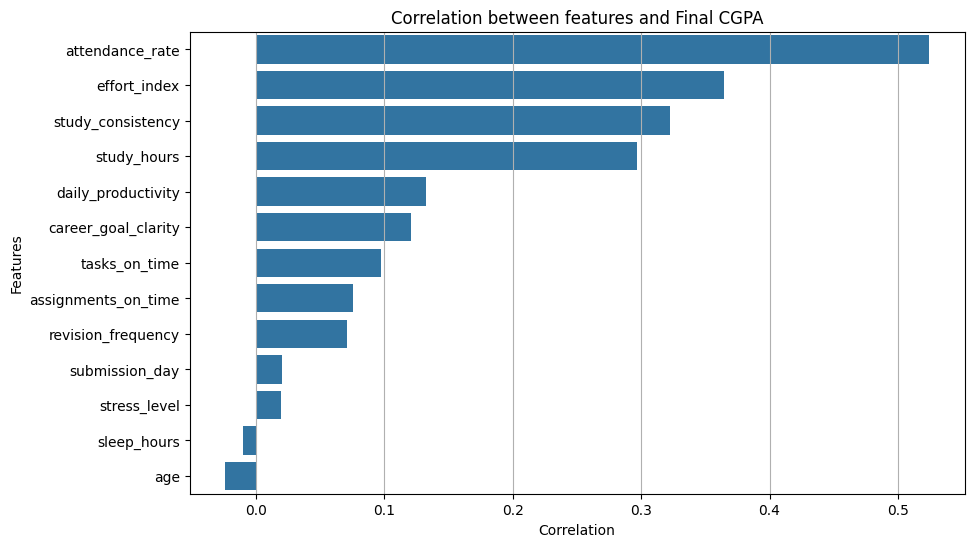

Strongest correlation: attendance_rate
Weakest correlation: age


In [20]:
numeric_features = [
    "study_hours",
    "sleep_hours",
    "attendance_rate",
    "study_consistency",
    "tasks_on_time",
    "assignments_on_time",
    "revision_frequency",
    "career_goal_clarity",
    "daily_productivity",
    "stress_level",
    "age",
    "submission_day",
    "effort_index"
]

correlations = df[
    numeric_features + ["final_cgpa"]
].corr(numeric_only=True)["final_cgpa"].drop(
    "final_cgpa"
).sort_values(ascending=False)

print("Correlation with final CGPA:")
display(correlations.to_frame("Correlation"))

# Correlation plot
plt.figure(figsize=(10, 6))

sns.barplot(
    x=correlations.values,
    y=correlations.index
)

plt.title("Correlation between features and Final CGPA")
plt.xlabel("Correlation")
plt.ylabel("Features")
plt.grid(axis="x")
plt.show()

print("Strongest correlation:", correlations.idxmax())
print("Weakest correlation:", correlations.idxmin())

In [21]:
# Compare risk level and CGPA category

risk_table = pd.crosstab(
    df["performance_risk_level"],
    df["cgpa_category"]
)

print("Performance Risk Level vs CGPA Category:")
display(risk_table)

Performance Risk Level vs CGPA Category:


cgpa_category,5.0 – 6.9,7.0 – 8.4,8.5 – 9.4,9.5 – 10.0
performance_risk_level,,,,
High Risk,188,221,39,4
Low Risk,0,4,89,83
Moderate Risk,48,195,234,95


Total cohort categories: 29
Categories with fewer than 10 observations: 12


cohort_code
BCom | Second Year (PG)                  9
BA | First Year (PG)                     8
BA | First Year (FY)                     7
BSc Cyber Security | Second Year (PG)    7
BCom | Final Year                        6
BBA | First Year (PG)                    6
BA | Second Year (PG)                    6
BBA | Final Year                         6
BSc IT | Second Year (PG)                5
BSc Cyber Security | Final Year          4
BBA | Second Year (PG)                   3
BA | Final Year                          3
Name: count, dtype: int64

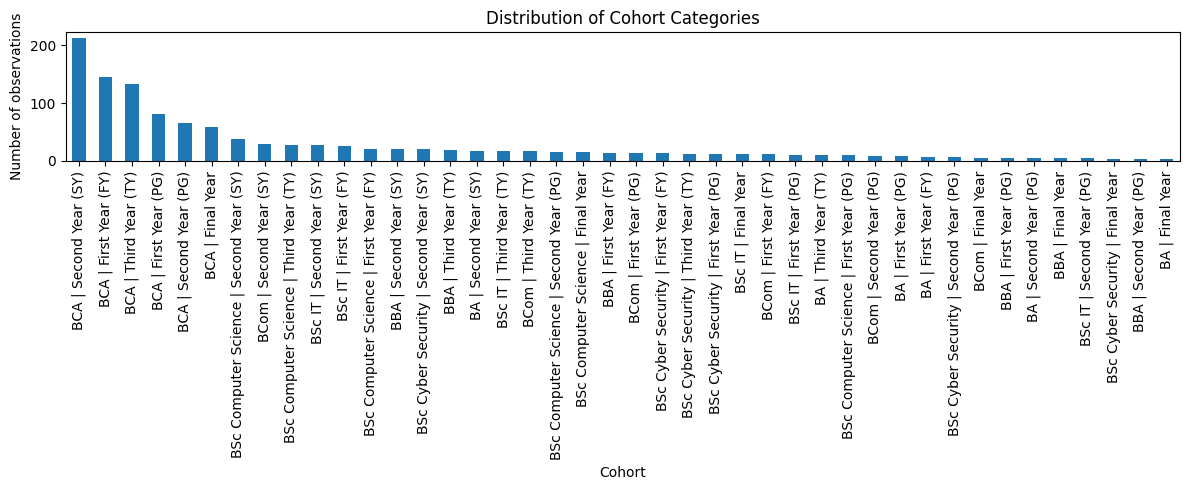

In [22]:
cohort_counts = df["cohort_code"].value_counts()

rare_categories = cohort_counts[
    cohort_counts < 10
]

print("Total cohort categories:",
      cohort_counts.nunique())

print("Categories with fewer than 10 observations:",
      len(rare_categories))

display(rare_categories)

plt.figure(figsize=(12, 5))

cohort_counts.plot(kind="bar")

plt.title("Distribution of Cohort Categories")
plt.xlabel("Cohort")
plt.ylabel("Number of observations")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

Already in chronological order: False


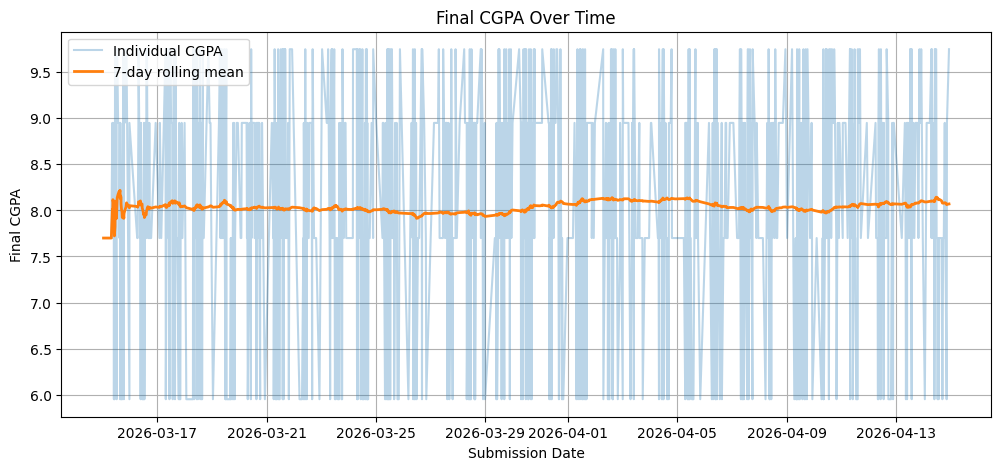

In [23]:
# Check original chronological order
is_chronological = df["timestamp"].is_monotonic_increasing

print("Already in chronological order:",
      is_chronological)

# Sort dataset
df = df.sort_values("timestamp").reset_index(drop=True)

# Plot final CGPA over time
daily_data = df.set_index("timestamp")["final_cgpa"]

rolling_mean = daily_data.rolling(
    "7D",
    min_periods=1
).mean()

plt.figure(figsize=(12, 5))

plt.plot(
    daily_data.index,
    daily_data.values,
    alpha=0.3,
    label="Individual CGPA"
)

plt.plot(
    rolling_mean.index,
    rolling_mean.values,
    linewidth=2,
    label="7-day rolling mean"
)

plt.title("Final CGPA Over Time")
plt.xlabel("Submission Date")
plt.ylabel("Final CGPA")
plt.legend()
plt.grid()
plt.show()

In [24]:
print("""
PART A - POTENTIAL RISKS

1. Missing values:
   Missing observations can affect model training.

2. Duplicate observations:
   Duplicates can cause data leakage if similar records
   appear in both training and testing sets.

3. Target leakage:
   Performance risk level may reveal information about
   the target and must not be used as a predictive feature.

4. Rare cohort categories:
   Categories with few observations may lead to overfitting.

5. Temporal drift:
   Changes over time may affect the generalization
   performance of models.
""")


PART A - POTENTIAL RISKS

1. Missing values:
   Missing observations can affect model training.

2. Duplicate observations:
   Duplicates can cause data leakage if similar records
   appear in both training and testing sets.

3. Target leakage:
   Performance risk level may reveal information about
   the target and must not be used as a predictive feature.

4. Rare cohort categories:
   Categories with few observations may lead to overfitting.

5. Temporal drift:
   Changes over time may affect the generalization
   performance of models.



PART B – Impact of Data Leakage and Evaluation Strategy

In [25]:
# Define target
target = "final_cgpa"

# Features used in Part B
features = [
    "study_hours",
    "sleep_hours",
    "attendance_rate",
    "study_consistency",
    "tasks_on_time",
    "assignments_on_time",
    "revision_frequency",
    "career_goal_clarity",
    "daily_productivity",
    "stress_level",
    "age",
    "submission_day"
]

X = df[features].copy()
y = df[target].copy()

# Remove rows with missing target
valid = y.notna() & df["timestamp"].notna()

X = X.loc[valid].reset_index(drop=True)
y = y.loc[valid].reset_index(drop=True)

# Rebuild chronological dataset
chronological_order = np.argsort(
    df.loc[valid, "timestamp"].values
)

X = X.iloc[chronological_order].reset_index(drop=True)
y = y.iloc[chronological_order].reset_index(drop=True)

# Chronological split: 80% train / 20% test
split_index = int(len(X) * 0.8)

X_train = X.iloc[:split_index].copy()
X_test = X.iloc[split_index:].copy()

y_train = y.iloc[:split_index].copy()
y_test = y.iloc[split_index:].copy()

print("Training size:", X_train.shape)
print("Testing size:", X_test.shape)

Training size: (960, 12)
Testing size: (240, 12)


In [26]:
def calculate_rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))


def evaluate_model(model, X_train, X_test, y_train, y_test):

    model.fit(X_train, y_train)

    train_predictions = model.predict(X_train)
    test_predictions = model.predict(X_test)

    train_rmse = calculate_rmse(
        y_train, train_predictions
    )

    test_rmse = calculate_rmse(
        y_test, test_predictions
    )

    return train_rmse, test_rmse


def create_numeric_pipeline(model, scaling=False):

    steps = [
        ("imputer", SimpleImputer(strategy="median"))
    ]

    if scaling:
        steps.append(
            ("scaler", StandardScaler())
        )

    steps.append(("model", model))

    return Pipeline(steps)

In [27]:
# Decision Tree model
tree = DecisionTreeRegressor(
    random_state=RANDOM_STATE
)

tree_pipeline = create_numeric_pipeline(tree)

# Random split
X_random_train, X_random_test, y_random_train, y_random_test = (
    train_test_split(
        X,
        y,
        test_size=0.2,
        random_state=RANDOM_STATE
    )
)

random_train_rmse, random_test_rmse = evaluate_model(
    clone(tree_pipeline),
    X_random_train,
    X_random_test,
    y_random_train,
    y_random_test
)

# Chronological split
chrono_train_rmse, chrono_test_rmse = evaluate_model(
    clone(tree_pipeline),
    X_train,
    X_test,
    y_train,
    y_test
)

# Baseline
baseline = DummyRegressor(strategy="mean")

baseline.fit(X_train, y_train)

baseline_predictions = baseline.predict(X_test)

baseline_rmse = calculate_rmse(
    y_test,
    baseline_predictions
)

# Results
part_b1_results = pd.DataFrame({
    "Strategy": [
        "Random Split",
        "Chronological Split",
        "Baseline"
    ],
    "Training RMSE": [
        random_train_rmse,
        chrono_train_rmse,
        calculate_rmse(
            y_train,
            baseline.predict(X_train)
        )
    ],
    "Testing RMSE": [
        random_test_rmse,
        chrono_test_rmse,
        baseline_rmse
    ]
})

display(part_b1_results)

,Strategy,Training RMSE,Testing RMSE
0,Random Split,4.622227e-16,1.686771
1,Chronological Split,4.134246e-16,2.090626
2,Baseline,1.268541e+00,1.236164


In [28]:
# Create a copy of the original dataframe
df_augmented = df.copy()

# Select 15% of observations randomly
sampled_rows = df.sample(
    frac=0.15,
    random_state=RANDOM_STATE
).copy()

# Generate new random timestamps within the survey period
rng = np.random.default_rng(RANDOM_STATE)

min_timestamp = df["timestamp"].min().value
max_timestamp = df["timestamp"].max().value

random_timestamps = pd.to_datetime(
    rng.integers(
        min_timestamp,
        max_timestamp,
        size=len(sampled_rows)
    )
)

sampled_rows["timestamp"] = random_timestamps

# Add duplicated observations
df_augmented = pd.concat(
    [df_augmented, sampled_rows],
    ignore_index=True
)

# Recalculate submission_day
df_augmented["submission_day"] = (
    df_augmented["timestamp"] - first_date
).dt.total_seconds() / (24 * 3600)

print("Original dataset size:", len(df))
print("Augmented dataset size:", len(df_augmented))

Original dataset size: 1200
Augmented dataset size: 1380


In [29]:
def prepare_chronological_split(data):

    data = data.sort_values("timestamp").reset_index(drop=True)

    data = data.dropna(subset=["final_cgpa"])

    X_data = data[features].copy()
    y_data = data["final_cgpa"].copy()

    split = int(len(data) * 0.8)

    return (
        X_data.iloc[:split],
        X_data.iloc[split:],
        y_data.iloc[:split],
        y_data.iloc[split:]
    )


# Strategy 1: Split before removing duplicates
X_tr_dup, X_te_dup, y_tr_dup, y_te_dup = (
    prepare_chronological_split(df_augmented)
)

train_rmse_dup, test_rmse_dup = evaluate_model(
    clone(tree_pipeline),
    X_tr_dup,
    X_te_dup,
    y_tr_dup,
    y_te_dup
)


# Strategy 2: Remove duplicates before splitting
df_clean = df_augmented.drop_duplicates(
    subset=[
        col for col in df_augmented.columns
        if col != "timestamp"
    ]
).copy()

X_tr_clean, X_te_clean, y_tr_clean, y_te_clean = (
    prepare_chronological_split(df_clean)
)

train_rmse_clean, test_rmse_clean = evaluate_model(
    clone(tree_pipeline),
    X_tr_clean,
    X_te_clean,
    y_tr_clean,
    y_te_clean
)


# Results
part_b2_results = pd.DataFrame({
    "Strategy": [
        "Split before removing duplicates",
        "Remove duplicates before splitting"
    ],
    "Training RMSE": [
        train_rmse_dup,
        train_rmse_clean
    ],
    "Testing RMSE": [
        test_rmse_dup,
        test_rmse_clean
    ]
})

display(part_b2_results)

,Strategy,Training RMSE,Testing RMSE
0,Split before removing duplicates,6.655973e-16,1.520682
1,Remove duplicates before splitting,6.655973e-16,1.520682


In [30]:
# Strategy 1: Scaling before splitting
# This intentionally introduces preprocessing leakage.

imputer_global = SimpleImputer(strategy="median")

X_imputed = imputer_global.fit_transform(X)

scaler_global = StandardScaler()

X_scaled = scaler_global.fit_transform(X_imputed)

X_scaled = pd.DataFrame(
    X_scaled,
    columns=features
)

X_global_train = X_scaled.iloc[:split_index]
X_global_test = X_scaled.iloc[split_index:]

knn_global = KNeighborsRegressor(
    n_neighbors=10
)

knn_global.fit(X_global_train, y_train)

pred_global_train = knn_global.predict(
    X_global_train
)

pred_global_test = knn_global.predict(
    X_global_test
)

global_train_rmse = calculate_rmse(
    y_train,
    pred_global_train
)

global_test_rmse = calculate_rmse(
    y_test,
    pred_global_test
)


# Strategy 2: Scaling inside Pipeline
knn_pipeline = create_numeric_pipeline(
    KNeighborsRegressor(n_neighbors=10),
    scaling=True
)

pipeline_train_rmse, pipeline_test_rmse = evaluate_model(
    clone(knn_pipeline),
    X_train,
    X_test,
    y_train,
    y_test
)


# Comparison
part_b3_results = pd.DataFrame({
    "Strategy": [
        "Scaling before splitting",
        "Scaling inside Pipeline"
    ],
    "Training RMSE": [
        global_train_rmse,
        pipeline_train_rmse
    ],
    "Testing RMSE": [
        global_test_rmse,
        pipeline_test_rmse
    ]
})

display(part_b3_results)

,Strategy,Training RMSE,Testing RMSE
0,Scaling before splitting,1.100140,1.185845
1,Scaling inside Pipeline,1.093132,1.190360


In [31]:
part_b_results = pd.concat(
    [
        part_b1_results.assign(Experiment="B.1"),
        part_b2_results.assign(Experiment="B.2"),
        part_b3_results.assign(Experiment="B.3")
    ],
    ignore_index=True
)

display(
    part_b_results[
        [
            "Experiment",
            "Strategy",
            "Training RMSE",
            "Testing RMSE"
        ]
    ]
)

,Experiment,Strategy,Training RMSE,Testing RMSE
0,B.1,Random Split,4.622227e-16,1.686771
1,B.1,Chronological Split,4.134246e-16,2.090626
2,B.1,Baseline,1.268541e+00,1.236164
3,B.2,Split before removing duplicates,6.655973e-16,1.520682
4,B.2,Remove duplicates before splitting,6.655973e-16,1.520682
5,B.3,Scaling before splitting,1.100140e+00,1.185845
6,B.3,Scaling inside Pipeline,1.093132e+00,1.190360


In [32]:
print("""
PART B - INTERPRETATION

B.1 Random vs Chronological Split:
Random splitting mixes observations from different dates.
Chronological splitting evaluates the ability of a model
to predict future observations. Therefore, their performance
can be different when temporal patterns exist.

B.2 Duplicate Leakage:
Duplicated observations can appear in both training and
testing sets. The model may recognize information already
seen during training, resulting in an overly optimistic
testing score.

B.3 Preprocessing Leakage:
Scaling the entire dataset before splitting allows information
from the test set to influence preprocessing statistics.
Using a Pipeline ensures that the scaler and imputer are
fitted only on training data.
""")


PART B - INTERPRETATION

B.1 Random vs Chronological Split:
Random splitting mixes observations from different dates.
Chronological splitting evaluates the ability of a model
to predict future observations. Therefore, their performance
can be different when temporal patterns exist.

B.2 Duplicate Leakage:
Duplicated observations can appear in both training and
testing sets. The model may recognize information already
seen during training, resulting in an overly optimistic
testing score.

B.3 Preprocessing Leakage:
Scaling the entire dataset before splitting allows information
from the test set to influence preprocessing statistics.
Using a Pipeline ensures that the scaler and imputer are
fitted only on training data.



PART C – Understanding and Diagnosing Overfitting

In [33]:
depths = [1, 2, 3, 5, 10, 20, None]

tree_results = []

for depth in depths:

    model = create_numeric_pipeline(
        DecisionTreeRegressor(
            max_depth=depth,
            random_state=RANDOM_STATE
        )
    )

    model.fit(X_train, y_train)

    train_predictions = model.predict(X_train)
    test_predictions = model.predict(X_test)

    train_rmse = calculate_rmse(
        y_train,
        train_predictions
    )

    test_rmse = calculate_rmse(
        y_test,
        test_predictions
    )

    generalization_gap = test_rmse - train_rmse

    tree_results.append({
        "Depth": str(depth),
        "Training RMSE": train_rmse,
        "Testing RMSE": test_rmse,
        "Generalization Gap": generalization_gap
    })


tree_results_df = pd.DataFrame(tree_results)

display(tree_results_df)

,Depth,Training RMSE,Testing RMSE,Generalization Gap
0,1,1.223105e+00,1.174393,-0.048712
1,2,1.184931e+00,1.145821,-0.039110
2,3,1.155347e+00,1.134088,-0.021259
3,5,1.075974e+00,1.152296,0.076322
4,10,6.913722e-01,2.028336,1.336964
5,20,5.155987e-02,2.098613,2.047053
6,None,4.134246e-16,2.090626,2.090626


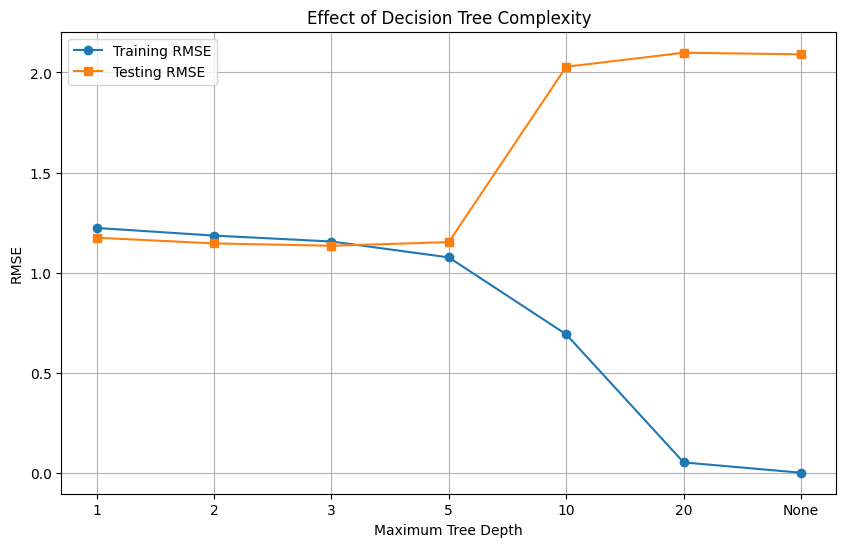

In [34]:
plt.figure(figsize=(10, 6))

plt.plot(
    tree_results_df["Depth"],
    tree_results_df["Training RMSE"],
    marker="o",
    label="Training RMSE"
)

plt.plot(
    tree_results_df["Depth"],
    tree_results_df["Testing RMSE"],
    marker="s",
    label="Testing RMSE"
)

plt.title("Effect of Decision Tree Complexity")
plt.xlabel("Maximum Tree Depth")
plt.ylabel("RMSE")
plt.legend()
plt.grid()

plt.show()

In [35]:
best_tree_depth = tree_results_df.loc[
    tree_results_df["Testing RMSE"].idxmin(),
    "Depth"
]

largest_gap_depth = tree_results_df.loc[
    tree_results_df["Generalization Gap"].idxmax(),
    "Depth"
]

print("Depth with lowest Testing RMSE:",
      best_tree_depth)

print("Depth with largest Generalization Gap:",
      largest_gap_depth)

Depth with lowest Testing RMSE: 3
Depth with largest Generalization Gap: None


In [36]:
degrees = [1, 2, 3, 5, 9, 15]

X_effort = df.loc[
    valid,
    ["effort_index"]
].iloc[chronological_order].reset_index(drop=True)

X_effort_train = X_effort.iloc[:split_index]

y_effort_train = y_train.copy()

tscv = TimeSeriesSplit(n_splits=5)

polynomial_results = []

for degree in degrees:

    model = Pipeline([
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "poly",
            PolynomialFeatures(
                degree=degree,
                include_bias=False
            )
        ),
        (
            "scaler",
            StandardScaler()
        ),
        (
            "regressor",
            LinearRegression()
        )
    ])

    scores = cross_val_score(
        model,
        X_effort_train,
        y_effort_train,
        cv=tscv,
        scoring="neg_mean_squared_error"
    )

    cv_rmse = np.sqrt(-scores)

    polynomial_results.append({
        "Degree": degree,
        "Mean CV RMSE": cv_rmse.mean(),
        "Std CV RMSE": cv_rmse.std()
    })


polynomial_results_df = pd.DataFrame(
    polynomial_results
)

display(polynomial_results_df)

,Degree,Mean CV RMSE,Std CV RMSE
0,1,1.185021,0.055195
1,2,1.184881,0.055158
2,3,1.186077,0.056192
3,5,1.192495,0.053353
4,9,1.203207,0.049814
5,15,1.208476,0.058800


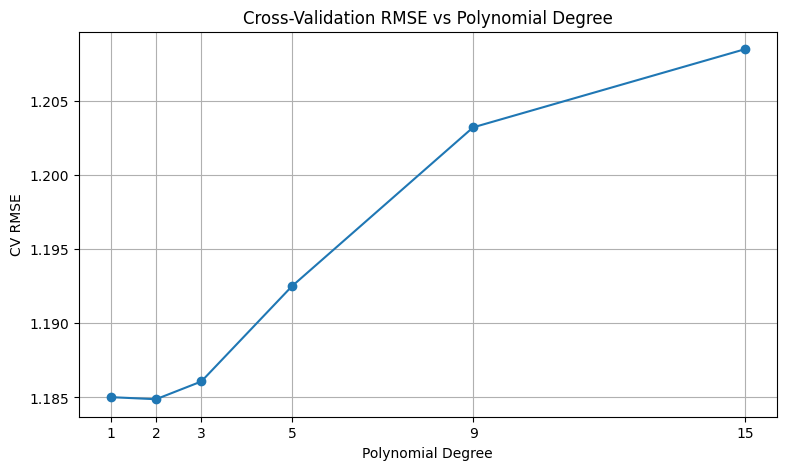

In [37]:
plt.figure(figsize=(9, 5))

plt.plot(
    polynomial_results_df["Degree"],
    polynomial_results_df["Mean CV RMSE"],
    marker="o"
)

plt.title("Cross-Validation RMSE vs Polynomial Degree")
plt.xlabel("Polynomial Degree")
plt.ylabel("CV RMSE")
plt.xticks(degrees)
plt.grid()

plt.show()

In [39]:
best_polynomial_degree = polynomial_results_df.loc[
    polynomial_results_df["Mean CV RMSE"].idxmin(),
    "Degree"
]

print("Best polynomial degree:",
      best_polynomial_degree)

print("""
PART C - INTERPRETATION

C.1 Decision Tree Complexity:
As tree depth increases, the model becomes more complex.
Training RMSE generally decreases, but testing RMSE may
increase. This difference indicates overfitting.

C.2 Polynomial Feature Complexity:
Increasing the polynomial degree allows the model to
represent more complex relationships. However, higher
degrees may increase variance and reduce generalization.

TimeSeriesSplit evaluates the models on successive
validation periods and helps identify a suitable degree.
""")

Best polynomial degree: 2

PART C - INTERPRETATION

C.1 Decision Tree Complexity:
As tree depth increases, the model becomes more complex.
Training RMSE generally decreases, but testing RMSE may
increase. This difference indicates overfitting.

C.2 Polynomial Feature Complexity:
Increasing the polynomial degree allows the model to
represent more complex relationships. However, higher
degrees may increase variance and reduce generalization.

TimeSeriesSplit evaluates the models on successive
validation periods and helps identify a suitable degree.



PART D – Improving Model Generalization

In [40]:
# Import clone
from sklearn.base import clone

# Features for Part D
part_d_features = features.copy()

X_d = df.loc[
    valid,
    part_d_features + ["cohort_code"]
].iloc[chronological_order].reset_index(drop=True)

y_d = y.copy()

X_d_train = X_d.iloc[:split_index].copy()
X_d_test = X_d.iloc[split_index:].copy()

y_d_train = y_d.iloc[:split_index].copy()
y_d_test = y_d.iloc[split_index:].copy()

numeric_columns = part_d_features

print("Part D training shape:", X_d_train.shape)
print("Part D testing shape:", X_d_test.shape)

Part D training shape: (960, 13)
Part D testing shape: (240, 13)


In [41]:
# Time Series Cross Validation
tscv = TimeSeriesSplit(n_splits=5)


def create_cohort_pipeline(approach):

    numeric_transformer = Pipeline([
        ("imputer", SimpleImputer(strategy="median"))
    ])

    if approach == "Rare-category grouping":

        categorical_transformer = Pipeline([
            (
                "imputer",
                SimpleImputer(
                    strategy="constant",
                    fill_value="Unknown"
                )
            ),
            (
                "encoder",
                OneHotEncoder(
                    min_frequency=10,
                    handle_unknown="infrequent_if_exist"
                )
            )
        ])

    elif approach == "Target encoding":

        categorical_transformer = Pipeline([
            (
                "imputer",
                SimpleImputer(
                    strategy="constant",
                    fill_value="Unknown"
                )
            ),
            (
                "encoder",
                TargetEncoder(
                    cv=5,
                    shuffle=False
                )
            )
        ])

    transformers = [
        ("numeric", numeric_transformer, numeric_columns)
    ]

    if approach != "Feature removal":

        transformers.append(
            (
                "categorical",
                categorical_transformer,
                ["cohort_code"]
            )
        )

    preprocessor = ColumnTransformer(transformers)

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        (
            "model",
            DecisionTreeRegressor(
                max_depth=5,
                random_state=RANDOM_STATE
            )
        )
    ])

    return pipeline


cohort_results = []

for approach in [
    "Rare-category grouping",
    "Target encoding",
    "Feature removal"
]:

    model = create_cohort_pipeline(approach)

    scores = cross_val_score(
        model,
        X_d_train,
        y_d_train,
        cv=tscv,
        scoring="neg_mean_squared_error"
    )

    rmse = np.sqrt(-scores)

    cohort_results.append({
        "Approach": approach,
        "Mean CV RMSE": rmse.mean(),
        "Std CV RMSE": rmse.std()
    })


cohort_results_df = pd.DataFrame(cohort_results)

display(cohort_results_df)

,Approach,Mean CV RMSE,Std CV RMSE
0,Rare-category grouping,1.372322,0.131221
1,Target encoding,1.359922,0.129253
2,Feature removal,1.370475,0.160208


Best cohort treatment: Target encoding


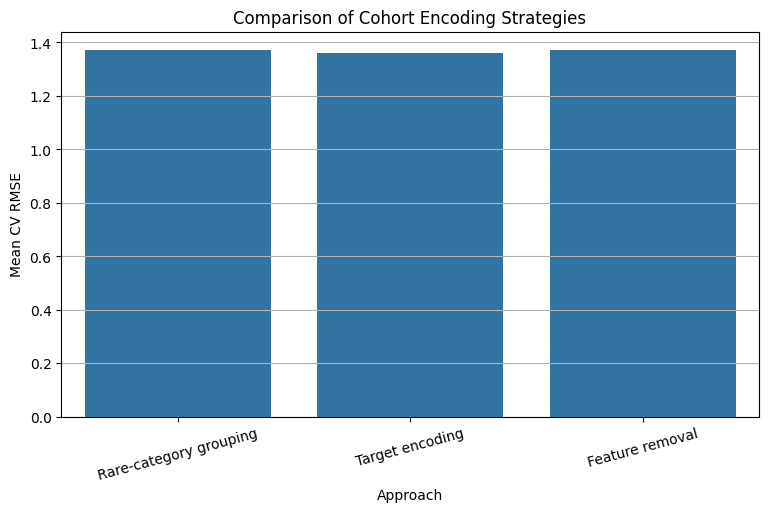

In [42]:
best_cohort_approach = cohort_results_df.loc[
    cohort_results_df["Mean CV RMSE"].idxmin(),
    "Approach"
]

print("Best cohort treatment:",
      best_cohort_approach)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=cohort_results_df,
    x="Approach",
    y="Mean CV RMSE"
)

plt.title("Comparison of Cohort Encoding Strategies")
plt.xlabel("Approach")
plt.ylabel("Mean CV RMSE")
plt.xticks(rotation=15)
plt.grid(axis="y")
plt.show()

In [43]:
# Features with and without submission_day
features_with_day = features.copy()

features_without_day = [
    col for col in features
    if col != "submission_day"
]


models_to_compare = {
    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        max_depth=5,
        random_state=RANDOM_STATE
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=60,
        learning_rate=0.05,
        max_depth=3,
        random_state=RANDOM_STATE
    )
}


feature_selection_results = []

for model_name, estimator in models_to_compare.items():

    for feature_type, selected_features in [
        ("With submission_day", features_with_day),
        ("Without submission_day", features_without_day)
    ]:

        pipeline = create_numeric_pipeline(
            clone(estimator)
        )

        scores = cross_val_score(
            pipeline,
            X_d_train[selected_features],
            y_d_train,
            cv=tscv,
            scoring="neg_mean_squared_error"
        )

        rmse = np.sqrt(-scores)

        feature_selection_results.append({
            "Model": model_name,
            "Features": feature_type,
            "Mean CV RMSE": rmse.mean(),
            "Std CV RMSE": rmse.std()
        })


feature_selection_df = pd.DataFrame(
    feature_selection_results
)

display(feature_selection_df)

,Model,Features,Mean CV RMSE,Std CV RMSE
0,Linear Regression,With submission_day,1.168810,0.064631
1,Linear Regression,Without submission_day,1.162906,0.062317
2,Decision Tree,With submission_day,1.370475,0.160208
3,Decision Tree,Without submission_day,1.310622,0.063966
4,Gradient Boosting,With submission_day,1.178994,0.069589
5,Gradient Boosting,Without submission_day,1.160046,0.056833


In [44]:
feature_summary = feature_selection_df.groupby(
    "Features"
)["Mean CV RMSE"].mean()

print("Average CV RMSE:")
display(feature_summary)

keep_submission_day = (
    feature_summary["With submission_day"]
    <
    feature_summary["Without submission_day"]
)

print("Keep submission_day:", keep_submission_day)

selected_features = (
    features_with_day
    if keep_submission_day
    else features_without_day
)

print("Selected features:")
print(selected_features)

Average CV RMSE:


Features
With submission_day       1.239426
Without submission_day    1.211192
Name: Mean CV RMSE, dtype: float64

Keep submission_day: False
Selected features:
['study_hours', 'sleep_hours', 'attendance_rate', 'study_consistency', 'tasks_on_time', 'assignments_on_time', 'revision_frequency', 'career_goal_clarity', 'daily_productivity', 'stress_level', 'age']


In [45]:
alphas = [0.001, 0.01, 0.1, 1, 10, 100]

regularization_results = []

X_effort_train = X_effort_train.copy()

# Linear Regression
linear_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    (
        "poly",
        PolynomialFeatures(
            degree=5,
            include_bias=False
        )
    ),
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

linear_scores = cross_val_score(
    linear_pipeline,
    X_effort_train,
    y_train,
    cv=tscv,
    scoring="neg_mean_squared_error"
)

regularization_results.append({
    "Model": "Linear Regression",
    "Alpha": None,
    "Mean CV RMSE": np.sqrt(-linear_scores).mean()
})


# Ridge and Lasso
for model_name, estimator in [
    ("Ridge", Ridge()),
    ("Lasso", Lasso(max_iter=100000))
]:

    for alpha in alphas:

        model = clone(estimator)
        model.set_params(alpha=alpha)

        pipeline = Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            (
                "poly",
                PolynomialFeatures(
                    degree=5,
                    include_bias=False
                )
            ),
            ("scaler", StandardScaler()),
            ("model", model)
        ])

        scores = cross_val_score(
            pipeline,
            X_effort_train,
            y_train,
            cv=tscv,
            scoring="neg_mean_squared_error"
        )

        regularization_results.append({
            "Model": model_name,
            "Alpha": alpha,
            "Mean CV RMSE": np.sqrt(-scores).mean()
        })


regularization_df = pd.DataFrame(
    regularization_results
)

display(regularization_df)

,Model,Alpha,Mean CV RMSE
0,Linear Regression,NaN,1.192495
1,Ridge,0.001,1.189033
2,Ridge,0.010,1.187866
3,Ridge,0.100,1.186407
4,Ridge,1.000,1.185750
5,Ridge,10.000,1.185497
6,Ridge,100.000,1.187956
7,Lasso,0.001,1.185457
8,Lasso,0.010,1.184759
9,Lasso,0.100,1.185740


In [46]:
best_regularization = {}

for model_name in ["Ridge", "Lasso"]:

    subset = regularization_df[
        regularization_df["Model"] == model_name
    ]

    best_row = subset.loc[
        subset["Mean CV RMSE"].idxmin()
    ]

    best_regularization[model_name] = best_row["Alpha"]

    print(
        model_name,
        "Best alpha:",
        best_row["Alpha"],
        "| CV RMSE:",
        round(best_row["Mean CV RMSE"], 4)
    )

Ridge Best alpha: 10.0 | CV RMSE: 1.1855
Lasso Best alpha: 0.01 | CV RMSE: 1.1848


In [47]:
# Train polynomial models on the complete training data

models_regularized = {
    "Linear Regression": LinearRegression(),

    "Ridge": Ridge(
        alpha=best_regularization["Ridge"]
    ),

    "Lasso": Lasso(
        alpha=best_regularization["Lasso"],
        max_iter=100000
    )
}

coefficient_results = []

for name, estimator in models_regularized.items():

    pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        (
            "poly",
            PolynomialFeatures(
                degree=5,
                include_bias=False
            )
        ),
        ("scaler", StandardScaler()),
        ("model", estimator)
    ])

    pipeline.fit(X_effort_train, y_train)

    coefficients = pipeline.named_steps["model"].coef_

    zero_coefficients = np.sum(
        np.isclose(coefficients, 0)
    )

    coefficient_results.append({
        "Model": name,
        "Number of coefficients": len(coefficients),
        "Zero coefficients": zero_coefficients
    })


coefficient_df = pd.DataFrame(
    coefficient_results
)

display(coefficient_df)

,Model,Number of coefficients,Zero coefficients
0,Linear Regression,5,0
1,Ridge,5,0
2,Lasso,5,4


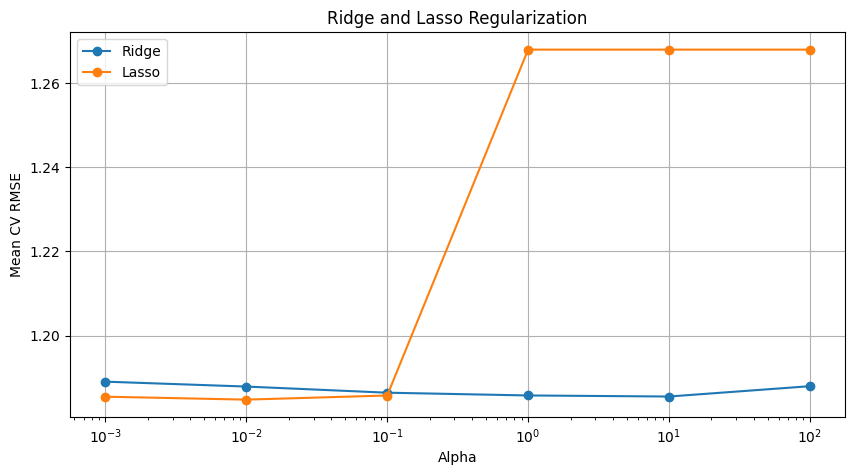

In [48]:
plt.figure(figsize=(10, 5))

for model_name in ["Ridge", "Lasso"]:

    subset = regularization_df[
        regularization_df["Model"] == model_name
    ]

    plt.plot(
        subset["Alpha"],
        subset["Mean CV RMSE"],
        marker="o",
        label=model_name
    )

plt.xscale("log")

plt.title("Ridge and Lasso Regularization")
plt.xlabel("Alpha")
plt.ylabel("Mean CV RMSE")

plt.legend()
plt.grid()

plt.show()

In [49]:
# Final feature matrix
final_features = selected_features.copy()

if best_cohort_approach != "Feature removal":
    final_features.append("cohort_code")

X_final = df.loc[
    valid,
    final_features
].iloc[chronological_order].reset_index(drop=True)

y_final = y.copy()

X_final_train = X_final.iloc[:split_index].copy()
X_final_test = X_final.iloc[split_index:].copy()

y_final_train = y_final.iloc[:split_index].copy()
y_final_test = y_final.iloc[split_index:].copy()

print("Final training dataset:", X_final_train.shape)
print("Final testing dataset:", X_final_test.shape)

Final training dataset: (960, 12)
Final testing dataset: (240, 12)


In [50]:
def create_final_preprocessor():

    transformers = [
        (
            "numeric",
            SimpleImputer(strategy="median"),
            selected_features
        )
    ]

    if best_cohort_approach == "Rare-category grouping":

        cat_pipeline = Pipeline([
            (
                "imputer",
                SimpleImputer(
                    strategy="constant",
                    fill_value="Unknown"
                )
            ),
            (
                "encoder",
                OneHotEncoder(
                    min_frequency=10,
                    handle_unknown="infrequent_if_exist"
                )
            )
        ])

        transformers.append(
            (
                "categorical",
                cat_pipeline,
                ["cohort_code"]
            )
        )

    elif best_cohort_approach == "Target encoding":

        cat_pipeline = Pipeline([
            (
                "imputer",
                SimpleImputer(
                    strategy="constant",
                    fill_value="Unknown"
                )
            ),
            (
                "encoder",
                TargetEncoder(
                    cv=5,
                    shuffle=False
                )
            )
        ])

        transformers.append(
            (
                "categorical",
                cat_pipeline,
                ["cohort_code"]
            )
        )

    return ColumnTransformer(transformers)

In [51]:
regularized_candidates = {}

for name, estimator in [
    (
        "Ridge",
        Ridge(alpha=best_regularization["Ridge"])
    ),
    (
        "Lasso",
        Lasso(
            alpha=best_regularization["Lasso"],
            max_iter=100000
        )
    )
]:

    pipeline = Pipeline([
        ("preprocessor", create_final_preprocessor()),
        ("scaler", StandardScaler(with_mean=False)),
        ("model", estimator)
    ])

    scores = cross_val_score(
        pipeline,
        X_final_train,
        y_final_train,
        cv=tscv,
        scoring="neg_mean_squared_error"
    )

    regularized_candidates[name] = np.sqrt(-scores).mean()


best_regularized_name = min(
    regularized_candidates,
    key=regularized_candidates.get
)

print("Best regularized model:",
      best_regularized_name)

print("Validation RMSE:",
      regularized_candidates[best_regularized_name])

Best regularized model: Lasso
Validation RMSE: 1.1655303884011299


In [52]:
depth_results_final = []

for depth in depths:

    pipeline = Pipeline([
        ("preprocessor", create_final_preprocessor()),
        (
            "model",
            DecisionTreeRegressor(
                max_depth=depth,
                random_state=RANDOM_STATE
            )
        )
    ])

    scores = cross_val_score(
        pipeline,
        X_final_train,
        y_final_train,
        cv=tscv,
        scoring="neg_mean_squared_error"
    )

    depth_results_final.append({
        "Depth": depth,
        "CV RMSE": np.sqrt(-scores).mean()
    })


depth_final_df = pd.DataFrame(depth_results_final)

display(depth_final_df)

best_final_depth = depth_final_df.loc[
    depth_final_df["CV RMSE"].idxmin(),
    "Depth"
]

print("Best Decision Tree depth:", best_final_depth)

,Depth,CV RMSE
0,1.0,1.232875
1,2.0,1.216486
2,3.0,1.235836
3,5.0,1.334852
4,10.0,1.527743
5,20.0,1.638523
6,NaN,1.638579


Best Decision Tree depth: 2.0


In [53]:
# Split training data into sub-training and validation blocks

early_split = int(len(X_final_train) * 0.85)

X_subtrain = X_final_train.iloc[:early_split]
y_subtrain = y_final_train.iloc[:early_split]

X_validation = X_final_train.iloc[early_split:]
y_validation = y_final_train.iloc[early_split:]


# Create pipeline
gb_pipeline = Pipeline([
    ("preprocessor", create_final_preprocessor()),
    (
        "model",
        GradientBoostingRegressor(
            n_estimators=500,
            learning_rate=0.05,
            max_depth=3,
            random_state=RANDOM_STATE
        )
    )
])


# Train on the first 85%
gb_pipeline.fit(X_subtrain, y_subtrain)

# Predict at each boosting stage
validation_predictions = list(
    gb_pipeline.named_steps["model"].staged_predict(
        gb_pipeline.named_steps["preprocessor"].transform(
            X_validation
        )
    )
)

# Calculate validation RMSE for every number of trees
gb_validation_rmse = [
    calculate_rmse(y_validation, prediction)
    for prediction in validation_predictions
]

best_n_estimators = np.argmin(
    gb_validation_rmse
) + 1

print("Optimal number of trees:", best_n_estimators)

print(
    "Best validation RMSE:",
    min(gb_validation_rmse)
)

Optimal number of trees: 68
Best validation RMSE: 1.0894644611168554


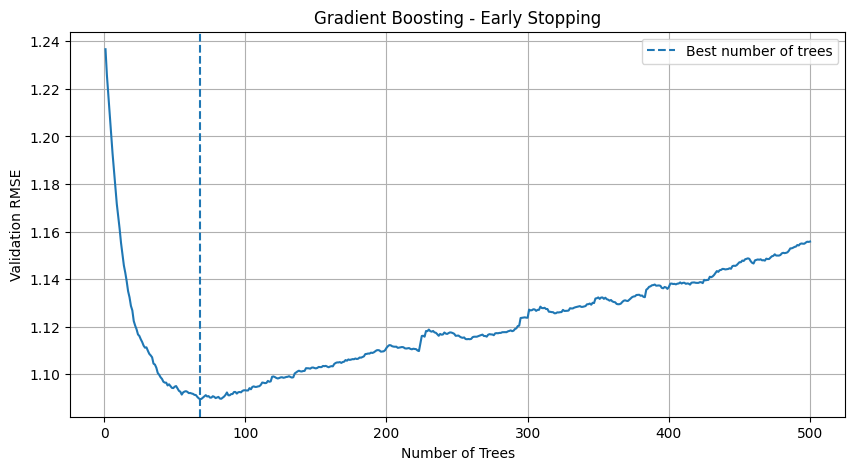

In [54]:
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(gb_validation_rmse) + 1),
    gb_validation_rmse
)

plt.axvline(
    best_n_estimators,
    linestyle="--",
    label="Best number of trees"
)

plt.title("Gradient Boosting - Early Stopping")
plt.xlabel("Number of Trees")
plt.ylabel("Validation RMSE")
plt.legend()
plt.grid()

plt.show()

In [55]:
# Select Ridge or Lasso and alpha on the final feature matrix

regularized_final_results = []

for model_name in ["Ridge", "Lasso"]:

    for alpha in alphas:

        if model_name == "Ridge":
            estimator = Ridge(alpha=alpha)
        else:
            estimator = Lasso(
                alpha=alpha,
                max_iter=100000
            )

        pipeline = Pipeline([
            ("preprocessor", create_final_preprocessor()),
            ("scaler", StandardScaler(with_mean=False)),
            ("model", estimator)
        ])

        scores = cross_val_score(
            pipeline,
            X_final_train,
            y_final_train,
            cv=tscv,
            scoring="neg_mean_squared_error"
        )

        regularized_final_results.append({
            "Model": model_name,
            "Alpha": alpha,
            "CV RMSE": np.sqrt(-scores).mean()
        })


regularized_final_df = pd.DataFrame(
    regularized_final_results
)

display(regularized_final_df)

best_regularized_row = regularized_final_df.loc[
    regularized_final_df["CV RMSE"].idxmin()
]

best_regularized_name = best_regularized_row["Model"]
best_final_alpha = best_regularized_row["Alpha"]

print("Selected model:", best_regularized_name)
print("Selected alpha:", best_final_alpha)

,Model,Alpha,CV RMSE
0,Ridge,0.001,1.170839
1,Ridge,0.010,1.170836
2,Ridge,0.100,1.170804
3,Ridge,1.000,1.170491
4,Ridge,10.000,1.167799
5,Ridge,100.000,1.159971
6,Lasso,0.001,1.170288
7,Lasso,0.010,1.165530
8,Lasso,0.100,1.155195
9,Lasso,1.000,1.268023


Selected model: Lasso
Selected alpha: 0.1


In [63]:
# 1. Linear Regression
linear_final = Pipeline([
    ("preprocessor", create_final_preprocessor()),
    ("scaler", StandardScaler(with_mean=False)),
    ("model", LinearRegression())
])


# 2. Best Ridge or Lasso
if best_regularized_name == "Ridge":
    regularized_estimator = Ridge(alpha=best_final_alpha)
else:
    regularized_estimator = Lasso(
        alpha=best_final_alpha,
        max_iter=100000
    )

regularized_final = Pipeline([
    ("preprocessor", create_final_preprocessor()),
    ("scaler", StandardScaler(with_mean=False)),
    ("model", regularized_estimator)
])


# 3. Best Decision Tree

tree_final = Pipeline([
    ("preprocessor", create_final_preprocessor()),
    (
        "model",
        DecisionTreeRegressor(
            max_depth=int(best_final_depth),
            random_state=RANDOM_STATE
        )
    )
])


# 4. Gradient Boosting
gradient_final = Pipeline([
    ("preprocessor", create_final_preprocessor()),
    (
        "model",
        GradientBoostingRegressor(
            n_estimators=best_n_estimators,
            learning_rate=0.05,
            max_depth=3,
            random_state=RANDOM_STATE
        )
    )
])


final_models = {
    "Linear Regression": linear_final,
    best_regularized_name: regularized_final,
    "Decision Tree": tree_final,
    "Gradient Boosting": gradient_final
}

# Fit all final models on the complete training set
for name, model in final_models.items():

    model.fit(
        X_final_train,
        y_final_train
    )

    print(name, "trained successfully!")

Linear Regression trained successfully!
Lasso trained successfully!
Decision Tree trained successfully!
Gradient Boosting trained successfully!


In [64]:
final_results = []


# Baseline
baseline_final = DummyRegressor(
    strategy="mean"
)

baseline_final.fit(
    X_final_train,
    y_final_train
)

baseline_train_predictions = baseline_final.predict(
    X_final_train
)

baseline_test_predictions = baseline_final.predict(
    X_final_test
)

final_results.append({
    "Model": "Baseline",
    "Training RMSE": calculate_rmse(
        y_final_train,
        baseline_train_predictions
    ),
    "Testing RMSE": calculate_rmse(
        y_final_test,
        baseline_test_predictions
    ),
    "Testing R2": r2_score(
        y_final_test,
        baseline_test_predictions
    )
})


# Evaluate all trained models
for name, model in final_models.items():

    train_predictions = model.predict(
        X_final_train
    )

    test_predictions = model.predict(
        X_final_test
    )

    final_results.append({
        "Model": name,

        "Training RMSE": calculate_rmse(
            y_final_train,
            train_predictions
        ),

        "Testing RMSE": calculate_rmse(
            y_final_test,
            test_predictions
        ),

        "Testing R2": r2_score(
            y_final_test,
            test_predictions
        )
    })


final_results_df = pd.DataFrame(
    final_results
)

display(
    final_results_df.round(4)
)

,Model,Training RMSE,Testing RMSE,Testing R2
0,Baseline,1.2685,1.2362,-0.0029
1,Linear Regression,1.1252,1.1016,0.2036
2,Lasso,1.1488,1.1114,0.1893
3,Decision Tree,1.1849,1.1458,0.1384
4,Gradient Boosting,1.0737,1.1050,0.1987
